<a href="https://colab.research.google.com/github/rezzz59/Hands-On-Large-Language-Models/blob/main/text_clasification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from datasets import load_dataset
# Memuat dataset Rotten Tomatoes mentah dengan path lengkap untuk menghindari bug resolusi URI
data = load_dataset("cornell-movie-review-data/rotten_tomatoes")

# Menampilkan data pertama dan kedua dari split train untuk mencocokkan dengan contoh Anda
print("Contoh teks asli dan label:")
display({
    'text': [data['train'][0]['text'], data['train'][1]['text']],
    'label': [data['train'][0]['label'], data['train'][1]['label']]
})

README.md:   0%|          | 0.00/7.46k [00:00<?, ?B/s]

train.parquet: reconstructing file:   0%|          |  0.00B /  699kB            

train.parquet: downloading bytes:           |  0.00B            

validation.parquet: reconstructing file:   0%|          |  0.00B / 90.0kB            

validation.parquet: downloading bytes:           |  0.00B            

test.parquet: reconstructing file:   0%|          |  0.00B / 92.2kB            

... (2 outputs left out)

Generating validation split:   0%|          | 0/1066 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1066 [00:00<?, ? examples/s]

Contoh teks asli dan label:


{'text': ['the rock is destined to be the 21st century\'s new " conan " and that he\'s going to make a splash even greater than arnold schwarzenegger , jean-claud van damme or steven segal .',
  'the gorgeously elaborate continuation of " the lord of the rings " trilogy is so huge that a column of words cannot adequately describe co-writer/director peter jackson\'s expanded vision of j . r . r . tolkien\'s middle-earth .'],
 'label': [1, 1]}

In [3]:
data

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 8530
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 1066
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 1066
    })
})

In [4]:
data['train'][0,-1]

{'text': ['the rock is destined to be the 21st century\'s new " conan " and that he\'s going to make a splash even greater than arnold schwarzenegger , jean-claud van damme or steven segal .',
  'things really get weird , though not particularly scary : the movie is all portent and no content .'],
 'label': [1, 0]}

In [5]:
from transformers import pipeline
# Path to our HF model
model_path = "cardiffnlp/twitter-roberta-base-sentiment-latest"
# Load model into pipeline
pipe = pipeline(
 model=model_path,
 tokenizer=model_path,
 return_all_scores=True,
 device="cuda:0"
)

config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  501MB            

model.safetensors: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

In [6]:
import numpy as np
from tqdm import tqdm
from transformers.pipelines.pt_utils import KeyDataset

# Jalankan inferensi
y_pred = []
# Kita hilangkan return_all_scores=True dari pipeline agar model langsung memberikan label terbaik
for output in tqdm(pipe(KeyDataset(data["test"], "text")), total=len(data["test"])):
    # Model mengembalikan dict seperti {'label': 'positive', 'score': 0.95}
    # Di mana labelnya bisa 'positive', 'neutral', atau 'negative'
    label = output['label']

    # Petakan label sentiment model ke biner (pos=1, neg/neutral=0)
    if label == 'positive':
        assignment = 1
    else:
        assignment = 0
    y_pred.append(assignment)



  0%|          | 0/1066 [00:00<?, ?it/s]

  0%|          | 1/1066 [00:02<40:22,  2.27s/it]

  0%|          | 2/1066 [00:02<17:44,  1.00s/it]

  1%|          | 10/1066 [00:02<02:29,  7.05it/s]

  2%|▏         | 19/1066 [00:02<01:08, 15.23it/s]

  3%|▎         | 29/1066 [00:02<00:40, 25.57it/s]

  4%|▎         | 39/1066 [00:02<00:28, 36.65it/s]

  5%|▍         | 48/1066 [00:02<00:22, 44.87it/s]

  5%|▌         | 58/1066 [00:03<00:18, 55.08it/s]

  6%|▋         | 68/1066 [00:03<00:15, 63.29it/s]

  7%|▋         | 78/1066 [00:03<00:14, 70.32it/s]

  8%|▊         | 87/1066 [00:03<00:15, 62.54it/s]

  9%|▉         | 97/1066 [00:03<00:13, 70.28it/s]

 10%|█         | 107/1066 [00:03<00:12, 74.19it/s]

 11%|█         | 116/1066 [00:03<00:12, 75.24it/s]

 12%|█▏        | 125/1066 [00:03<00:12, 76.70it/s]

 13%|█▎        | 134/1066 [00:03<00:12, 75.48it/s]

 14%|█▎        | 145/1066 [00:04<00:11, 83.22it/s]

 15%|█▍        | 155/1066 [00:04<00:10, 87.66it/s]

 16%|█▌        | 166/1066 [00:04<0

In [7]:
from sklearn.metrics import classification_report

def evaluate_performance(y_true, y_pred):
    """Create and return the classification report"""
    performance = classification_report(
        y_true, y_pred,
        target_names=["Negative Review", "Positive Review"]
    )
    return performance

# Memanggil fungsi dengan data aktual (label asli vs hasil prediksi)
report = evaluate_performance(data["test"]["label"], y_pred)
print(report)

                 precision    recall  f1-score   support

Negative Review       0.68      0.94      0.79       533
Positive Review       0.91      0.56      0.69       533

       accuracy                           0.75      1066
      macro avg       0.79      0.75      0.74      1066
   weighted avg       0.79      0.75      0.74      1066



#Supervised Classification

In [8]:
from sentence_transformers import SentenceTransformer
# Load model
model = SentenceTransformer("sentence-transformers/all-mpnet-base-v2")
# Convert text to embeddings
train_embeddings = model.encode(data["train"]["text"], show_progress_bar=True)
test_embeddings = model.encode(data["test"]["text"], show_progress_bar=True)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/267 [00:00<?, ?it/s]

Batches:   0%|          | 0/34 [00:00<?, ?it/s]

In [12]:
train_embeddings.shape, test_embeddings.shape

((8530, 768), (1066, 768))

In [13]:
from sklearn.linear_model import LogisticRegression
# Train a logistic regression on our train embeddings
clf = LogisticRegression(random_state=42)
clf.fit(train_embeddings, data["train"]["label"])

LogisticRegression(random_state=42)

In [17]:
# Predict previously unseen instances
y_pred = clf.predict(test_embeddings)
evaluate_performance(data["test"]["label"], y_pred)

'                 precision    recall  f1-score   support\n\nNegative Review       0.85      0.86      0.85       533\nPositive Review       0.86      0.85      0.85       533\n\n       accuracy                           0.85      1066\n      macro avg       0.85      0.85      0.85      1066\n   weighted avg       0.85      0.85      0.85      1066\n'

##**What If We Do Not Have Labeled Data?**
In our previous example, we had labeled data that we could leverage, but this might
not always be the case in practice. Getting labeled data is a resource-intensive task
that can require significant human labor. Moreover, is it actually worthwhile to collect
these labels?
To test this, we can perform zero-shot classification, where we have no labeled data
to explore whether the task seems feasible. Although we know the definition of
the labels (their names), we do not have labeled data to support them. Zero-shot
classification attempts to predict the labels of input text even though it was not
trained on them, as shown in Figure 4-13.

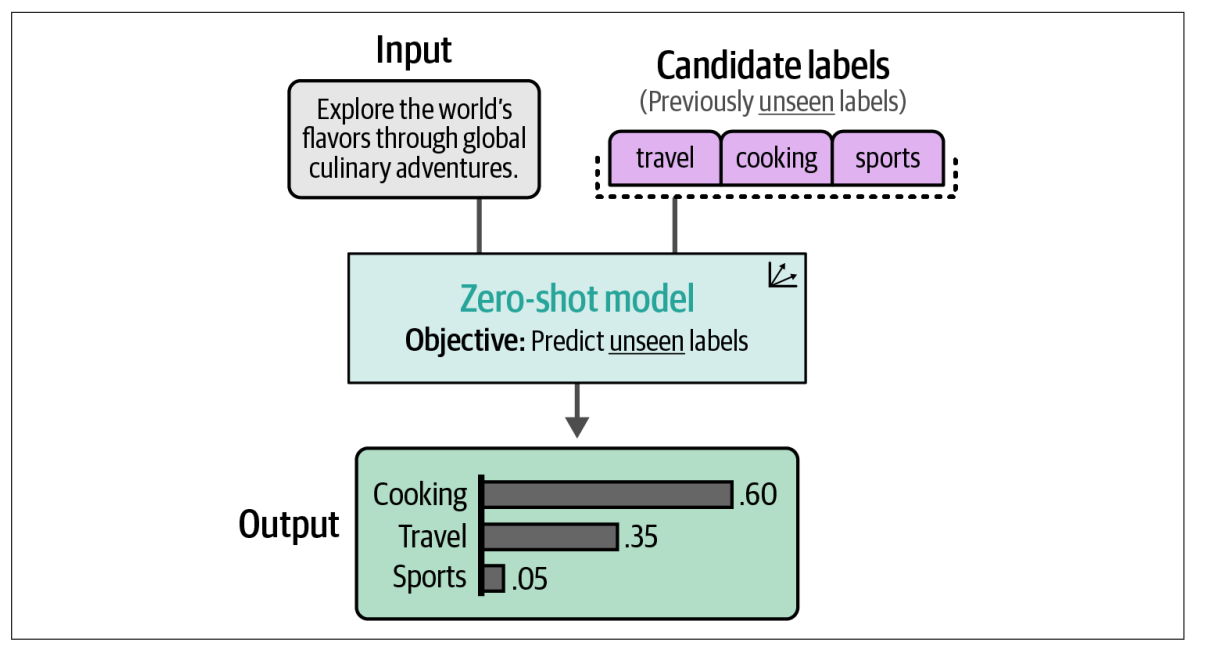

---



In [18]:
# Create embeddings for our labels
label_embeddings = model.encode(["A negative review", "A positive review"])

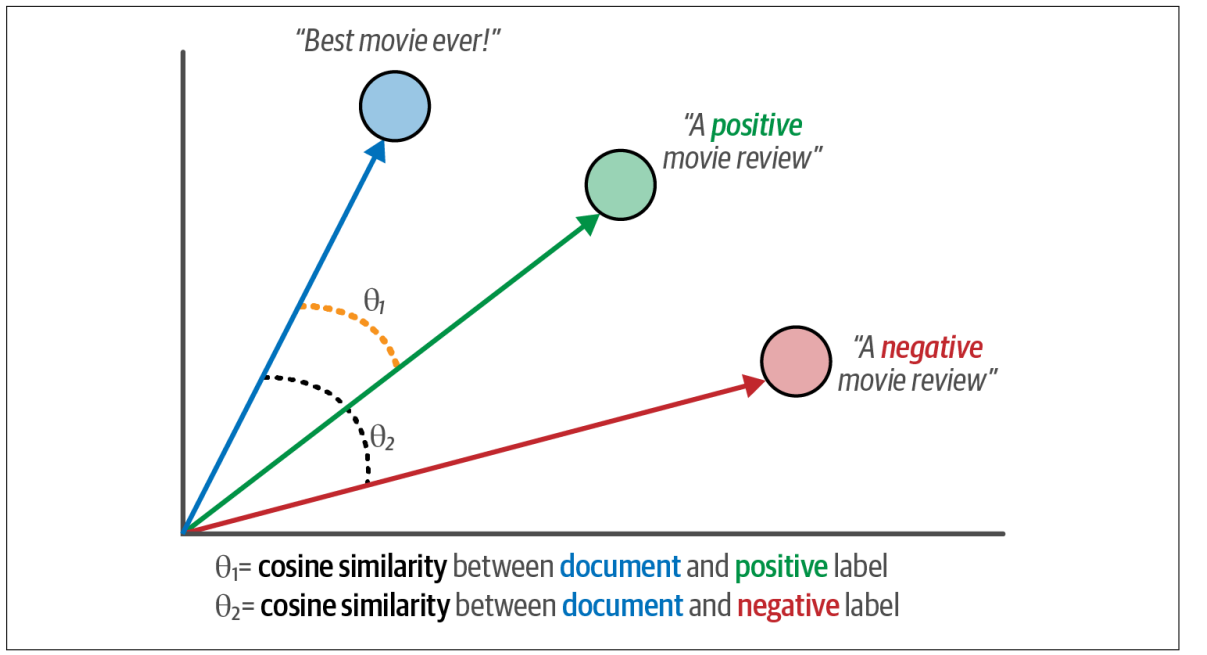

In [19]:
from sklearn.metrics.pairwise import cosine_similarity
# Find the best matching label for each document
sim_matrix = cosine_similarity(test_embeddings, label_embeddings)
y_pred = np.argmax(sim_matrix, axis=1)

In [20]:
evaluate_performance(data["test"]["label"], y_pred)

'                 precision    recall  f1-score   support\n\nNegative Review       0.78      0.77      0.78       533\nPositive Review       0.77      0.79      0.78       533\n\n       accuracy                           0.78      1066\n      macro avg       0.78      0.78      0.78      1066\n   weighted avg       0.78      0.78      0.78      1066\n'